In [1]:
import dask
dask.config.set({'dataframe.query-planning': False})

import os
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import hdf5plugin
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

import scvi

/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/scvi_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Upload files and models

In [2]:
adata = ad.read_h5ad("/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/objects/xenium_sc_sn_proseg_aging.h5ad")

In [3]:
adata.obs['cells_spatial'].value_counts()

cells_spatial
spatial    3531679
cells       972869
Name: count, dtype: int64

In [4]:
model = scvi.model.SCVI.load(
    "/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/models/scvi_sc_sn_xenium_proseg_aging/",
    adata
)

INFO     File                                                                                                      
         /home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/models/scvi_sc_sn_xenium_proseg_aging/mo
         del.pt already downloaded                                                                                 


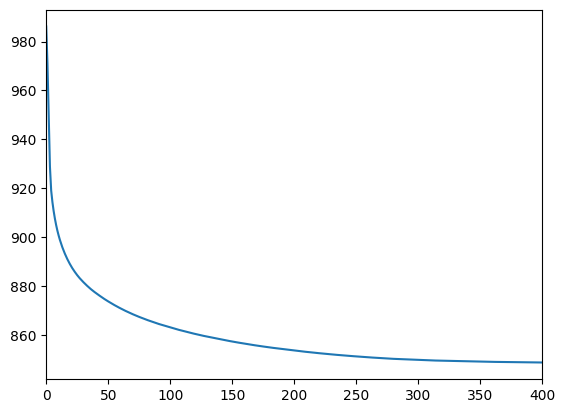

In [5]:
## Plot training history
plt.plot(model.history['elbo_train'][:]);
plt.xlim(0, len(model.history['elbo_train']));

In [6]:
latent = model.get_latent_representation()

In [7]:
## Add scVI latent space to original object
adata.obsm["X_scVI_shortlist_v1"] = latent

In [8]:
adata

AnnData object with n_obs × n_vars = 4504548 × 5043
    obs: 'sample_ID', 'donor', 'chemistry_simple', 'cells_spatial', '_scvi_batch', '_scvi_labels'
    uns: '_scvi_uuid', '_scvi_manager_uuid'
    obsm: '_scvi_extra_categorical_covs', 'X_scVI_shortlist_v1'
    layers: 'counts'

In [9]:
adata.write_h5ad("/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/objects/xenium_sc_sn_proseg_scvi_aging.h5ad")

### Clustering  

In [1]:
import os
import warnings
from pathlib import Path
    
import anndata as ad
import rapids_singlecell as rsc
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt


/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/rapids_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
adata = ad.read_h5ad("/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/objects/xenium_sc_sn_proseg_scvi_aging.h5ad")

In [3]:
adata.obs['cells_spatial'].value_counts()

cells_spatial
spatial    3531679
cells       972869
Name: count, dtype: int64

In [4]:
## Find neighbors, run Leiden clustering and UMAP
rsc.pp.neighbors(adata, use_rep="X_scVI_shortlist_v1", n_neighbors=50)


In [11]:
rsc.tl.leiden(adata, resolution=0.8, key_added='X_scVI_shortlist_v1_leiden_1')

In [12]:
adata.obs['X_scVI_shortlist_v1_leiden_1']

sc_TA13072046-ACACCCTTCAGCACAT    8
sc_TA13072046-GCATGTACATGTAGTC    8
sc_TA13072046-CCGGTAGTCAGCTTAG    8
sc_TA13072046-GGCCGATCAGTCGTGC    2
sc_TA13072046-CGATCGGGTACGCTGC    8
                                 ..
xenium_A67-233791                 8
xenium_A67-233792                 8
xenium_A67-233793                 5
xenium_A67-233794                 8
xenium_A67-233795                 8
Name: X_scVI_shortlist_v1_leiden_1, Length: 4504548, dtype: category
Categories (17, object): ['0', '1', '2', '3', ..., '13', '14', '15', '16']

In [7]:
rsc.tl.umap(adata, min_dist = 0.1, spread = 1)

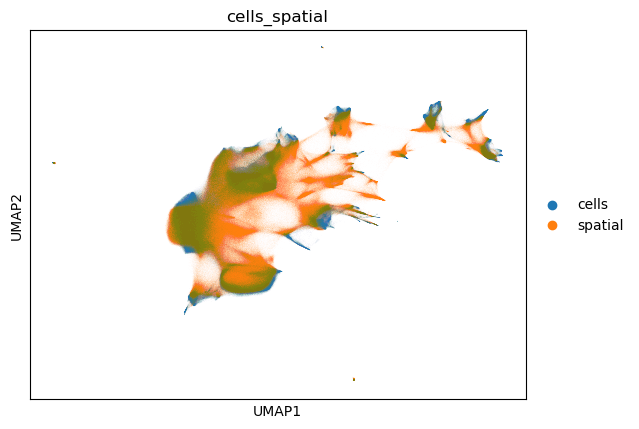

In [8]:
sc.pl.umap(adata, color=['cells_spatial'])

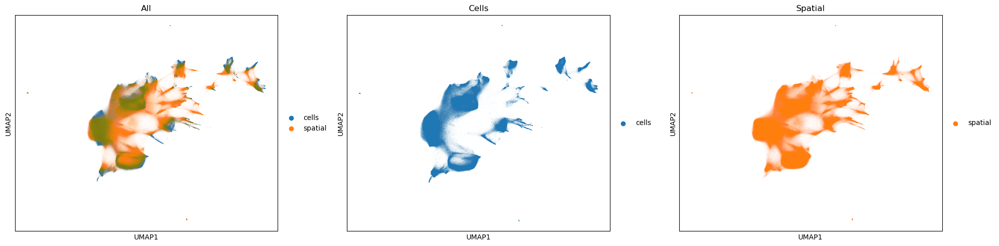

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

sc.pl.umap(adata, color='cells_spatial', ax=axes[0], show=False)
axes[0].set_title('All')

sc.pl.umap(adata[adata.obs['cells_spatial']=='cells'],
           color='cells_spatial', ax=axes[1], show=False)
axes[1].set_title('Cells')

sc.pl.umap(adata[adata.obs['cells_spatial']=='spatial'],
           color='cells_spatial', ax=axes[2], show=False)
axes[2].set_title('Spatial')

plt.tight_layout()
plt.show()

In [16]:
sc.pp.normalize_total(adata, target_sum=1e4)

sc.pp.log1p(adata)

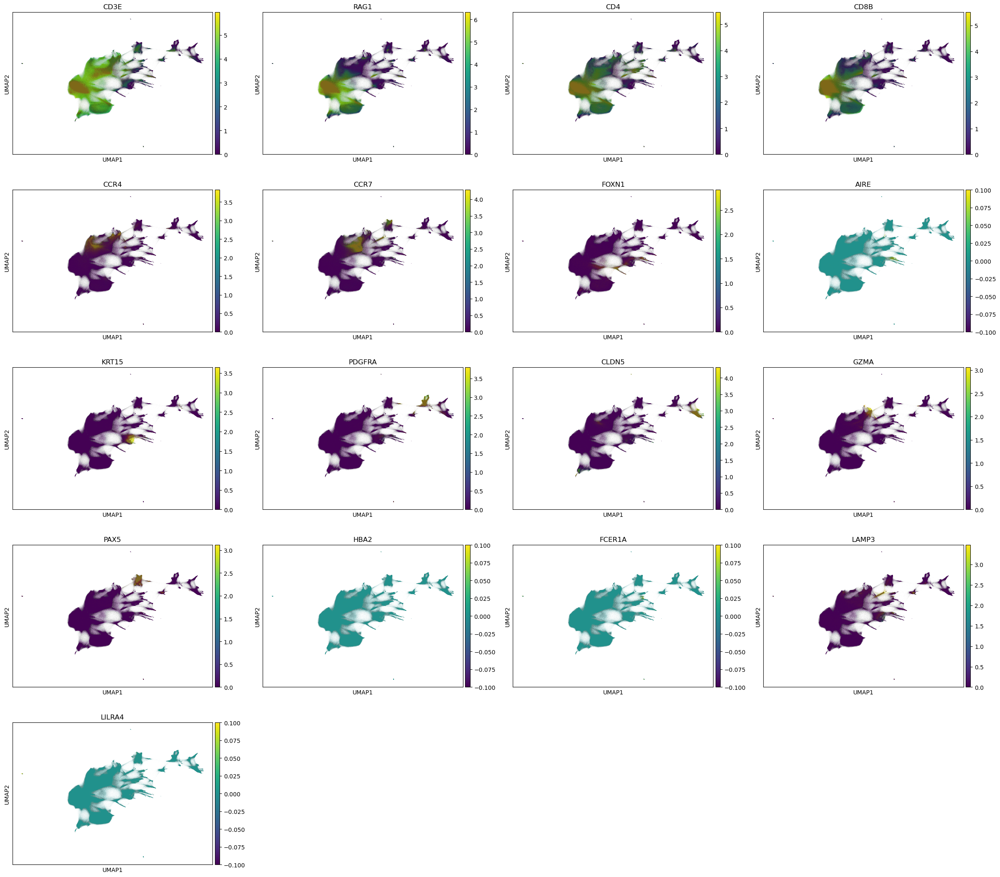

In [17]:
sc.pl.umap(adata, color=['CD3E', 'RAG1', 'CD4', 'CD8B', 'CCR4', 'CCR7', 'FOXN1', 'AIRE', 'KRT15',
                                'PDGFRA', 'CLDN5', 'GZMA', 'PAX5', 'HBA2', 'FCER1A', 'LAMP3', 'LILRA4'], vmax='p99')


In [ ]:
sc_anno = pd.read_csv('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/vk348/thymus_ageing_atlas/General_analysis/data/objects/rna/thyAgeing_all_scvi_v5_2025-10-15_curatedAnno_v11.csv')

In [ ]:
sc.pl.umap(adata[adata.obs['cells_spatial']!='spatial'], color=['cell_type_level_0'])

In [18]:
adata.write_h5ad('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/objects/xenium_sc_sn_proseg_scvi_plot_aging.h5ad')

### KNN label transfer (scanpy env)

In [1]:
import dask
dask.config.set({'dataframe.query-planning': False})

import os
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import hdf5plugin
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

In [3]:
adata_plot = sc.read_h5ad('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/objects/xenium_sc_sn_proseg_scvi_plot_aging.h5ad')

In [4]:
## Split into reference and query
adata_ref = adata_plot[adata_plot.obs['cells_spatial'] == 'cells']
adata_query = adata_plot[adata_plot.obs['cells_spatial'] == 'spatial']

In [11]:
sc_anno = pd.read_csv('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/vk348/thymus_ageing_atlas/General_analysis/data/objects/rna/thyAgeing_all_scvi_v5_2025-10-15_curatedAnno_v11.csv')

In [10]:
scell_adata = ad.read_h5ad('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/vk348/thymus_ageing_atlas/General_analysis/data/objects/rna/thyAgeing_all_scvi_v6_2026-05-01.zarr')

In [13]:
sc_anno_fil = sc_anno[sc_anno['Unnamed: 0'].isin(scell_adata.obs_names[scell_adata.obs["age_group"] != "aged"])]

In [14]:
sc_anno_fil

,Unnamed: 0,anno_status,qc_status,taa_l0,taa_l1,taa_l2,taa_l2_v2,taa_l3,taa_l3_v2,taa_l4,taa_l5
0,TA13072046-ACACCCTTCAGCACAT,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
1,TA13072046-GCATGTACATGTAGTC,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
2,TA13072046-CCGGTAGTCAGCTTAG,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
3,TA13072046-GGCCGATCAGTCGTGC,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
4,TA13072046-CGATCGGGTACGCTGC,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
...,...,...,...,...,...,...,...,...,...,...,...
1025293,THY_81-GTTGAACAGGGTGAGG,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)
1025294,THY_81-AACCTTTCAGTCGGAA,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)
1025295,THY_81-ATGCATGAGAAGCGCT,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)
1025296,THY_81-ATGGAGGGTAAGATTG,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)


In [6]:
adata_ref

View of AnnData object with n_obs × n_vars = 972869 × 5043
    obs: 'sample_ID', 'donor', 'chemistry_simple', 'cells_spatial', '_scvi_batch', '_scvi_labels', 'X_scVI_shortlist_v1_leiden_1'
    uns: 'X_scVI_shortlist_v1_leiden_1', '_scvi_manager_uuid', '_scvi_uuid', 'cells_spatial_colors', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI_shortlist_v1', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [7]:
adata_ref.obs_names

Index(['sc_TA13072046-ACACCCTTCAGCACAT', 'sc_TA13072046-GCATGTACATGTAGTC',
       'sc_TA13072046-CCGGTAGTCAGCTTAG', 'sc_TA13072046-GGCCGATCAGTCGTGC',
       'sc_TA13072046-CGATCGGGTACGCTGC', 'sc_TA13072046-CTGCGGAAGCCACTAT',
       'sc_TA13072046-GGACGTCGTCTCTTAT', 'sc_TA13072046-AGCTCTCAGTTATCGC',
       'sc_TA13072046-ATTCTACCACGGATAG', 'sc_TA13072046-CAAGTTGGTCAAAGCG',
       ...
       'sc_THY_81-GGAATCTCATCGATGT', 'sc_THY_81-GTGGGAACAAAGCGTG',
       'sc_THY_81-CGTGCTTCAGCTACCG', 'sc_THY_81-TATTTCGCATACAGAA',
       'sc_THY_81-CGTGTCTCATTGTAGC', 'sc_THY_81-GTTGAACAGGGTGAGG',
       'sc_THY_81-AACCTTTCAGTCGGAA', 'sc_THY_81-ATGCATGAGAAGCGCT',
       'sc_THY_81-ATGGAGGGTAAGATTG', 'sc_THY_81-GAAGGACTCTCGTCAC'],
      dtype='object', length=972869)

In [15]:
sc_anno_fil['Unnamed: 0'] = "sc_" + sc_anno_fil['Unnamed: 0']

/tmp/ipykernel_21971/2430481941.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sc_anno_fil['Unnamed: 0'] = "sc_" + sc_anno_fil['Unnamed: 0']


In [16]:
sc_anno_fil

,Unnamed: 0,anno_status,qc_status,taa_l0,taa_l1,taa_l2,taa_l2_v2,taa_l3,taa_l3_v2,taa_l4,taa_l5
0,sc_TA13072046-ACACCCTTCAGCACAT,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
1,sc_TA13072046-GCATGTACATGTAGTC,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
2,sc_TA13072046-CCGGTAGTCAGCTTAG,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
3,sc_TA13072046-GGCCGATCAGTCGTGC,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
4,sc_TA13072046-CGATCGGGTACGCTGC,include,PASS,Stroma,Fb,Fb,Fb,Fb-interlo,Fb-interlo,Fb-interlo,Fb-interlo
...,...,...,...,...,...,...,...,...,...,...,...
1025293,sc_THY_81-GTTGAACAGGGTGAGG,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)
1025294,sc_THY_81-AACCTTTCAGTCGGAA,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)
1025295,sc_THY_81-ATGCATGAGAAGCGCT,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)
1025296,sc_THY_81-ATGGAGGGTAAGATTG,include,PASS,Lymphoid,T,T_dev,T_DN,T_DN,T_DN,T_DN(Q),T_DN(Q)


In [17]:
(adata_ref.obs_names == sc_anno_fil['Unnamed: 0']).all()

np.True_

In [31]:
adata_ref.obs['taa_l0'] = list(sc_anno_fil['taa_l0'])
adata_ref.obs['taa_l1'] = list(sc_anno_fil['taa_l1'])
adata_ref.obs['taa_l2'] = list(sc_anno_fil['taa_l2'])
adata_ref.obs['taa_l3'] = list(sc_anno_fil['taa_l3'])
adata_ref.obs['taa_l4'] = list(sc_anno_fil['taa_l4'])
adata_ref.obs['taa_l5'] = list(sc_anno_fil['taa_l5'])
adata_ref.obs['taa_l2_v2'] = list(sc_anno_fil['taa_l2_v2'])
adata_ref.obs['taa_l3_v2'] = list(sc_anno_fil['taa_l3_v2'])

In [32]:
adata_ref.obs['taa_l2']

sc_TA13072046-ACACCCTTCAGCACAT       Fb
sc_TA13072046-GCATGTACATGTAGTC       Fb
sc_TA13072046-CCGGTAGTCAGCTTAG       Fb
sc_TA13072046-GGCCGATCAGTCGTGC       Fb
sc_TA13072046-CGATCGGGTACGCTGC       Fb
                                  ...  
sc_THY_81-GTTGAACAGGGTGAGG        T_dev
sc_THY_81-AACCTTTCAGTCGGAA        T_dev
sc_THY_81-ATGCATGAGAAGCGCT        T_dev
sc_THY_81-ATGGAGGGTAAGATTG        T_dev
sc_THY_81-GAAGGACTCTCGTCAC        T_dev
Name: taa_l2, Length: 972869, dtype: object

In [33]:
adata_ref.obs['taa_l3_v2']

sc_TA13072046-ACACCCTTCAGCACAT    Fb-interlo
sc_TA13072046-GCATGTACATGTAGTC    Fb-interlo
sc_TA13072046-CCGGTAGTCAGCTTAG    Fb-interlo
sc_TA13072046-GGCCGATCAGTCGTGC    Fb-interlo
sc_TA13072046-CGATCGGGTACGCTGC    Fb-interlo
                                     ...    
sc_THY_81-GTTGAACAGGGTGAGG              T_DN
sc_THY_81-AACCTTTCAGTCGGAA              T_DN
sc_THY_81-ATGCATGAGAAGCGCT              T_DN
sc_THY_81-ATGGAGGGTAAGATTG              T_DN
sc_THY_81-GAAGGACTCTCGTCAC              T_DN
Name: taa_l3_v2, Length: 972869, dtype: object

In [34]:
adata_query

View of AnnData object with n_obs × n_vars = 3531679 × 5043
    obs: 'sample_ID', 'donor', 'chemistry_simple', 'cells_spatial', '_scvi_batch', '_scvi_labels', 'X_scVI_shortlist_v1_leiden_1'
    uns: 'X_scVI_shortlist_v1_leiden_1', '_scvi_manager_uuid', '_scvi_uuid', 'cells_spatial_colors', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI_shortlist_v1', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [35]:
import scarches as sca

/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
 captum (see https://github.com/pytorch/captum).
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/site-packages/scarches/plotting/scvi_eval.py:13: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=200, frameon=False)
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/site-packages/scarches/plotting/trvae_eval.py:13: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=200, frameon=False)


In [36]:
## Defining a function to train a kNN classifier and make predictions:
def get_kNN_predictions(adata_ref, adata_query, train_emb, k, label_key):
    ## Use the weighted kNN classifier from scArches utils to predict annotations at all levels
    knn_transformer = sca.utils.knn.weighted_knn_trainer(
        train_adata=adata_ref,
        train_adata_emb=train_emb,  # location of our joint embedding
        n_neighbors=k,
    )

    ## Predict (and keep track of uncertainty)
    labels, uncert = sca.utils.knn.weighted_knn_transfer(
        query_adata=adata_query,
        query_adata_emb=train_emb,  # location of our embedding
        label_keys=label_key,  # (start of) obs column name(s) for which to transfer labels
        knn_model=knn_transformer,
        ref_adata_obs=adata_ref.obs,
    )
    return (labels, uncert)

In [37]:
## Transfer HTSA labels
labels, uncert = get_kNN_predictions(adata_ref, adata_query, 'X_scVI_shortlist_v1', 20, 'taa_l')


Weighted KNN with n_neighbors = 20 ... 

/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/site-packages/scarches/utils/knn.py:130: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  uncertainties.iloc[i][j] = (max(1 - best_prob, 0))
/rfs/project/rfs-iCNyzSAau

finished!


In [38]:
labels

,taa_l0,taa_l1,taa_l2,taa_l3,taa_l4,taa_l5,taa_l2_v2,taa_l3_v2
xenium_A45-2,Epithelial,TEC,Fb,Fb-interm,Fb-interm,Fb-interm,Fb,Fb-interm
xenium_A45-5,Epithelial,TEC,TEC-EMT,TEC-EMT,TEC-EMT,TEC-EMT,TEC-EMT,TEC-EMT
xenium_A45-10,Stroma,Fb,Fb,Fb-interm,Fb-interm,Fb-interm,Fb,Fb-interm
xenium_A45-13,Stroma,Fb,Fb,Fb-interlo,TEC-EMT,TEC-EMT,Fb,Fb-interlo
xenium_A45-19,Stroma,Fb,Fb,Fb-perilo,Fb-perilo,Fb-perilo,Fb,Fb-perilo
...,...,...,...,...,...,...,...,...
xenium_A67-233791,Stroma,Fb,Fb,Fb-perilo,Fb-perilo,Fb-perilo,Fb,Fb-perilo
xenium_A67-233792,Stroma,Fb,Fb,Fb-perilo,Fb-perilo,Fb-perilo,Fb,Fb-perilo
xenium_A67-233793,Vasculature,EC,EC-blood,EC-cap,EC-cap,EC-cap,EC-blood,EC-cap
xenium_A67-233794,Stroma,Fb,Fb,Fb-perilo,Fb-perilo_COLEC11,Fb-perilo_COLEC11,Fb,Fb-perilo


In [39]:
adata_query.obs['level_0_pred'] = labels['taa_l0'].copy()
adata_query.obs['level_0_prob'] = (1-uncert['taa_l0'])
adata_query.obs['level_1_pred'] = labels['taa_l1'].copy()
adata_query.obs['level_1_prob'] = (1-uncert['taa_l1'])
adata_query.obs['level_2_pred'] = labels['taa_l2'].copy()
adata_query.obs['level_2_prob'] = (1-uncert['taa_l2'])
adata_query.obs['level_3_pred'] = labels['taa_l3'].copy()
adata_query.obs['level_3_prob'] = (1-uncert['taa_l3'])
adata_query.obs['level_4_pred'] = labels['taa_l4'].copy()
adata_query.obs['level_4_prob'] = (1-uncert['taa_l4'])
adata_query.obs['level_5_pred'] = labels['taa_l5'].copy()
adata_query.obs['level_5_prob'] = (1-uncert['taa_l5'])
adata_query.obs['level_2v2_pred'] = labels['taa_l2_v2'].copy()
adata_query.obs['level_2v2_prob'] = (1-uncert['taa_l2_v2'])
adata_query.obs['level_3v2_pred'] = labels['taa_l3_v2'].copy()
adata_query.obs['level_3v2_prob'] = (1-uncert['taa_l3_v2'])

/tmp/ipykernel_21971/1728492863.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_query.obs['level_0_pred'] = labels['taa_l0'].copy()


In [40]:
adata_query.obs["level_0_prob"] = adata_query.obs["level_0_prob"].astype(float)
adata_query.obs["level_1_prob"] = adata_query.obs["level_1_prob"].astype(float)
adata_query.obs["level_2_prob"] = adata_query.obs["level_2_prob"].astype(float)
adata_query.obs["level_3_prob"] = adata_query.obs["level_3_prob"].astype(float)
adata_query.obs["level_4_prob"] = adata_query.obs["level_4_prob"].astype(float)
adata_query.obs["level_5_prob"] = adata_query.obs["level_5_prob"].astype(float)
adata_query.obs["level_2v2_prob"] = adata_query.obs["level_2v2_prob"].astype(float)
adata_query.obs["level_3v2_prob"] = adata_query.obs["level_3v2_prob"].astype(float)

In [41]:
adata_query

AnnData object with n_obs × n_vars = 3531679 × 5043
    obs: 'sample_ID', 'donor', 'chemistry_simple', 'cells_spatial', '_scvi_batch', '_scvi_labels', 'X_scVI_shortlist_v1_leiden_1', 'level_0_pred', 'level_0_prob', 'level_1_pred', 'level_1_prob', 'level_2_pred', 'level_2_prob', 'level_3_pred', 'level_3_prob', 'level_4_pred', 'level_4_prob', 'level_5_pred', 'level_5_prob', 'level_2v2_pred', 'level_2v2_prob', 'level_3v2_pred', 'level_3v2_prob'
    uns: 'X_scVI_shortlist_v1_leiden_1', '_scvi_manager_uuid', '_scvi_uuid', 'cells_spatial_colors', 'log1p', 'neighbors', 'umap'
    obsm: 'X_scVI_shortlist_v1', 'X_umap', '_scvi_extra_categorical_covs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [42]:
adata_query.write_h5ad('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/objects/xenium_aging_labels.h5ad')

### Plot labels

In [ ]:
adata_query = sc.read_h5ad('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/objects/xenium_aging_labels.h5ad')

In [43]:
adata_query.obs["level_0_pred"].value_counts()

level_0_pred
Lymphoid       2826113
Epithelial      323785
Myeloid         158844
Vasculature     122530
Stroma          100407
Name: count, dtype: int64

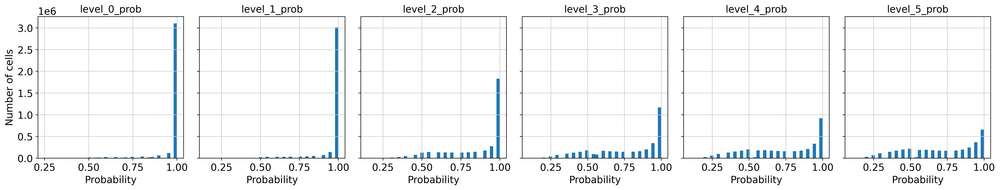

In [45]:
prob_cols = [
    "level_0_prob",
    "level_1_prob",
    "level_2_prob",
    "level_3_prob",
    "level_4_prob",
    "level_5_prob",
]

fig, axes = plt.subplots(1, 6, figsize=(20, 4), sharey=True)

for ax, col in zip(axes, prob_cols):
    values = adata_query.obs[col].astype(float)
    ax.hist(values, bins=40)
    ax.set_title(col)
    ax.set_xlabel("Probability")

axes[0].set_ylabel("Number of cells")

plt.tight_layout()
plt.show()

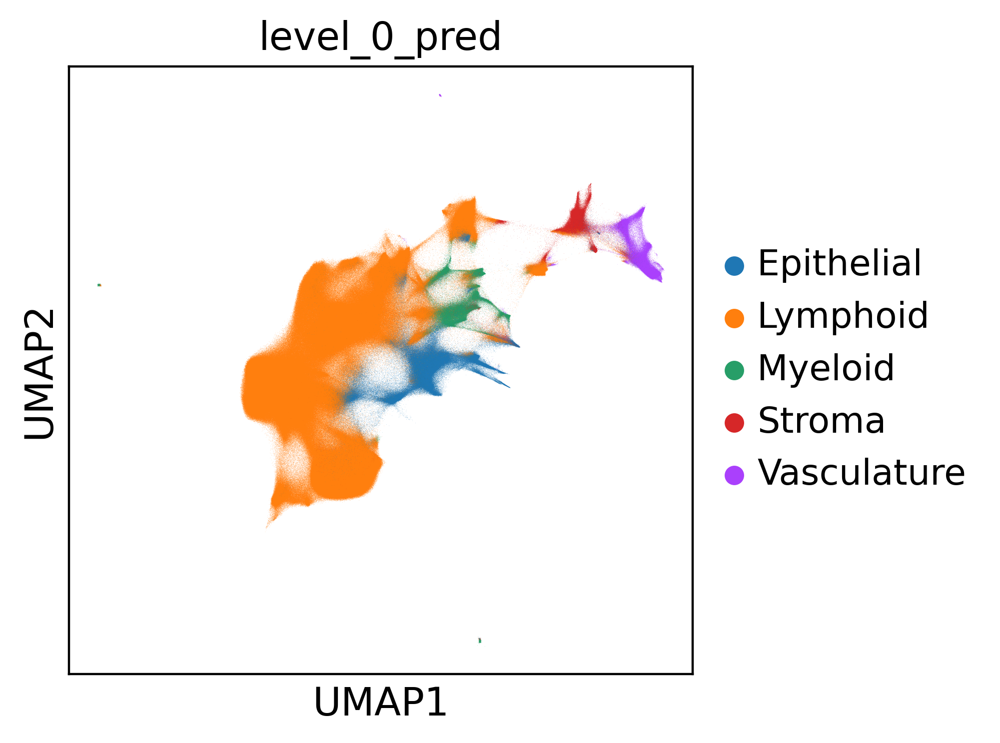

In [46]:
sc.pl.umap(adata_query, color=['level_0_pred'])

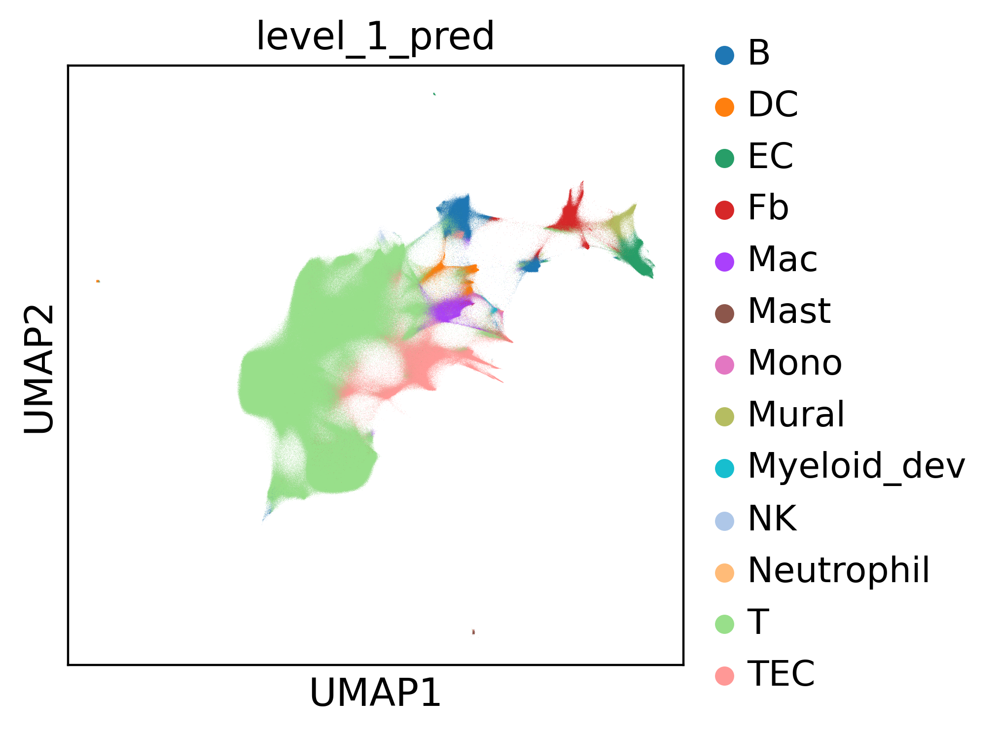

In [47]:
sc.pl.umap(adata_query, color=['level_1_pred'])

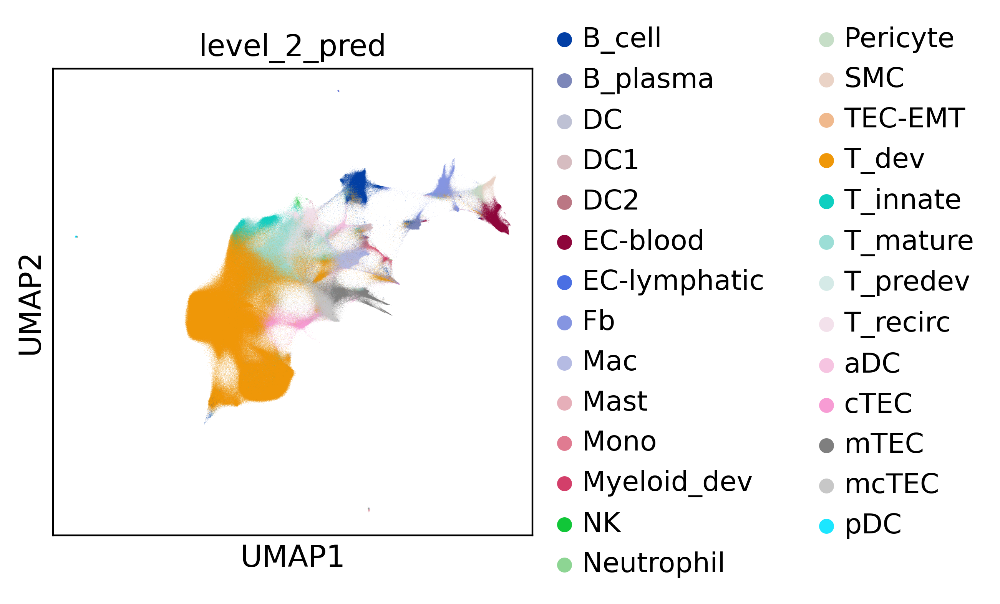

In [48]:
sc.pl.umap(adata_query, color=['level_2_pred'])

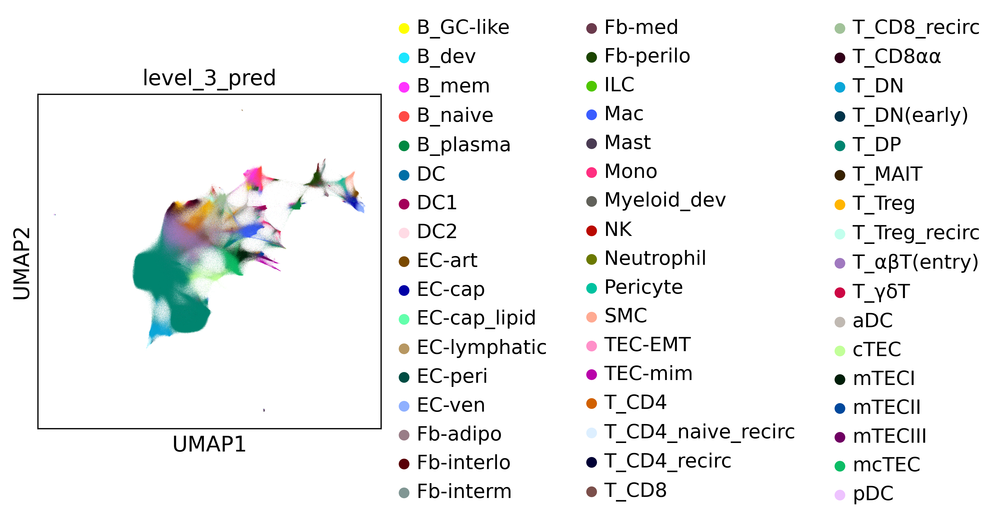

In [49]:
sc.pl.umap(adata_query, color=['level_3_pred'])

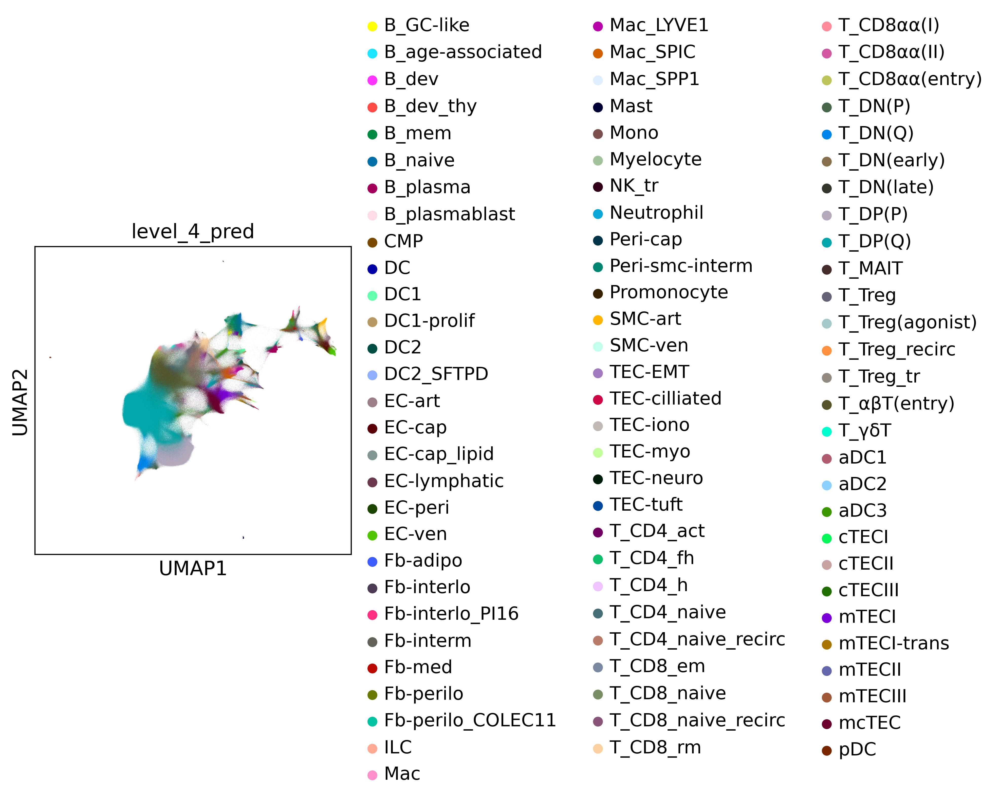

In [50]:
sc.pl.umap(adata_query, color=['level_4_pred'])

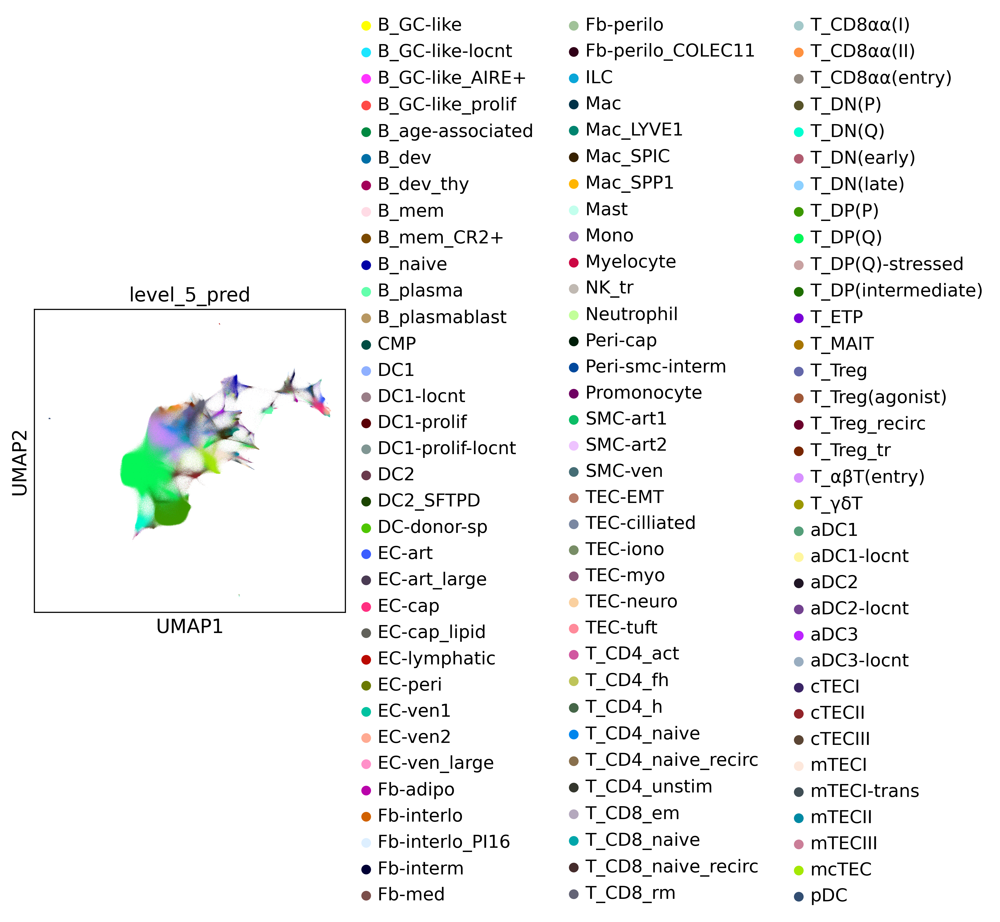

In [51]:
sc.pl.umap(adata_query, color=['level_5_pred'])

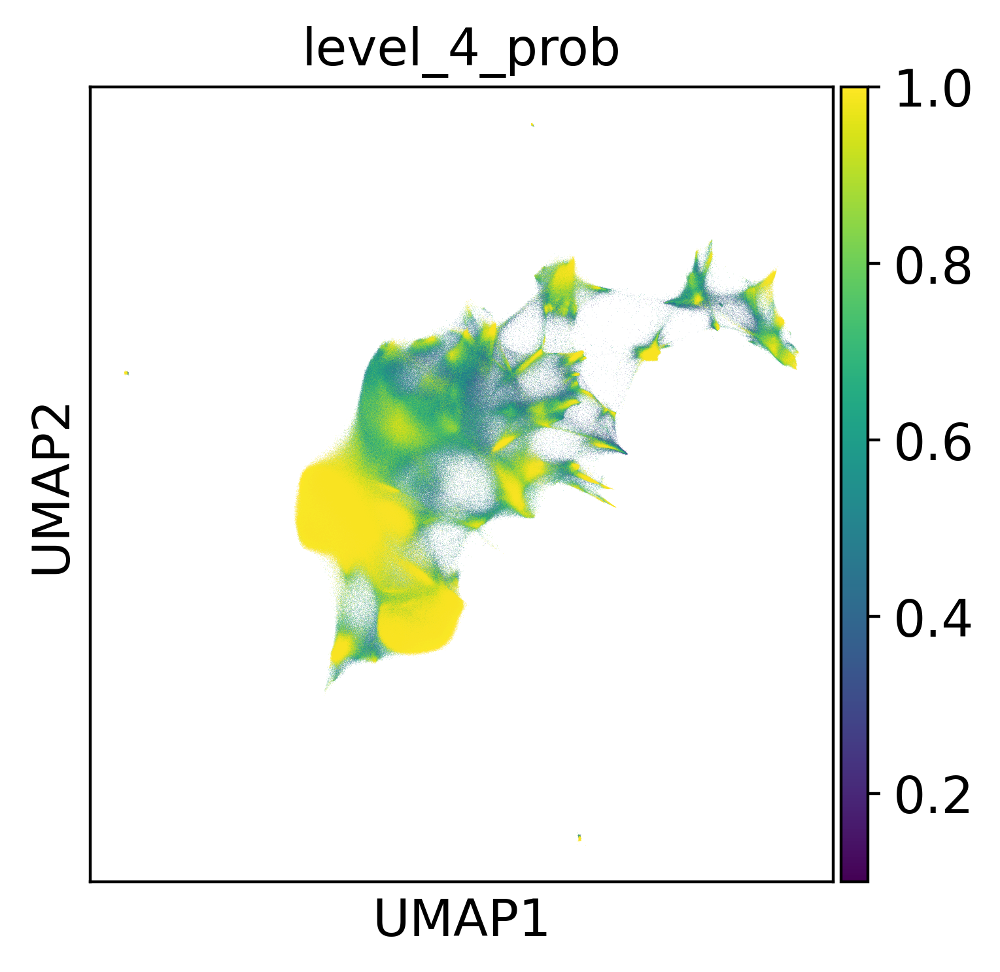

In [52]:
sc.pl.umap(adata_query, color=['level_4_prob'])

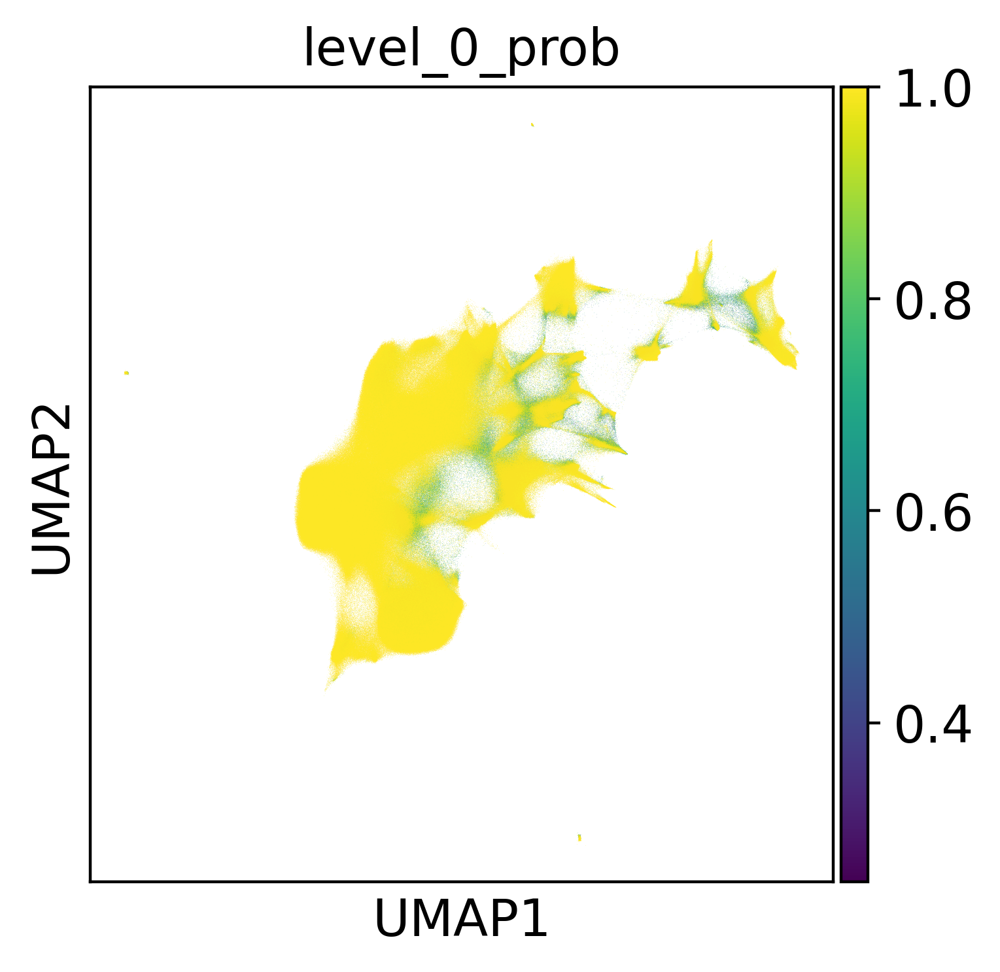

In [53]:
sc.pl.umap(adata_query, color=['level_0_prob'])